# **Step 1 of 7: HR Data Preprocessing for Clustering**

Clustering has **no target column** to tell us if the result is right, so the quality of the **input data** matters even more than in supervised learning: dirty or badly scaled data gives wrong clusters.

**Project steps**

| Step | Notebook | Purpose |
|---|---|---|
| **1** | **01_HR_Data_Preprocessing** (this one) | clean the raw data, choose features, scale, check clusterability |
| 2 | 02_KMeansPlusPlus_Clustering | K-Means++ |
| 3 | 03_Hierarchical_Clustering | Hierarchical (agglomerative) |
| 4 | 04_DBSCAN_Clustering | DBSCAN |
| 5 | 05_OPTICS_Clustering | OPTICS |
| 6 | 06_HDBSCAN_Clustering | HDBSCAN |
| 7 | 07_Best_Model_Selection | tune all algorithms, compare, pick and save the best |

**What this notebook does**
1. Load the raw data and check its quality (missing values, duplicates, wrong types, impossible values)
2. Clean it (duplicates, text, numbers, impossible values, missing values)
3. Encode categories, exclude columns that must not be clustered
4. Outlier analysis
5. Feature selection (correlation, VIF, continuous vs few-value columns)
6. Scaling
7. Check if the data has cluster structure at all (Hopkins statistic) and look at PCA
8. Save the files used by steps 2 to 7

> The raw data here is **synthetic demo data** (made to contain typical real-world problems). If `hr_raw_data.csv` is not found, it is generated in the next cell. To use your **own HR file**: save it as `hr_raw_data.csv` (an `employee_id` column is needed) and adapt the column names / cleaning rules in sections 3 and 4.

### 1. Import and load the raw data

In [1]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
warnings.filterwarnings('ignore')

from sklearn.preprocessing import StandardScaler, RobustScaler, MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
sns.set_theme(style='whitegrid')

RAW_FILE = 'hr_raw_data.csv'
steps_log = []          # every cleaning action is written here (and saved at the end)

Demo data generator (used **only** if `hr_raw_data.csv` does not exist):

In [2]:
import numpy as np, pandas as pd

def make_raw_hr_data(seed=42):
    """Synthetic RAW HR data with typical real-world problems."""
    rng = np.random.default_rng(seed)
    segs = {
        'Engaged high performers': (0.30, (0.80, 0.08), (0.85, 0.07), (4.5, 0.8), (205, 18), (4, 1.3), [0.15, 0.50, 0.35]),
        'Burned-out overworked':   (0.20, (0.25, 0.10), (0.88, 0.07), (6.0, 0.7), (272, 18), (4, 1.0), [0.55, 0.38, 0.07]),
        'Disengaged underused':    (0.25, (0.40, 0.10), (0.52, 0.07), (2.3, 0.6), (145, 16), (3, 1.0), [0.55, 0.38, 0.07]),
        'Loyal long-tenure':       (0.25, (0.65, 0.12), (0.70, 0.08), (3.8, 0.8), (180, 20), (8, 1.6), [0.10, 0.45, 0.45]),
    }
    n = 1500; n_out = int(n * 0.03); rows = []
    for name, (share, sat, ev, proj, hrs, ten, sal) in segs.items():
        m = int((n - n_out) * share)
        rows.append(pd.DataFrame({
            'satisfaction_level': np.clip(rng.normal(*sat, m), 0.09, 1), 'last_evaluation': np.clip(rng.normal(*ev, m), 0.36, 1),
            'number_project': np.clip(np.round(rng.normal(*proj, m)), 2, 7), 'average_monthly_hours': np.clip(np.round(rng.normal(*hrs, m)), 96, 310),
            'time_spend_company': np.clip(np.round(rng.normal(*ten, m)), 2, 10),
            'salary': rng.choice(['low', 'medium', 'high'], size=m, p=sal), 'segment_true': name}))
    rows.append(pd.DataFrame({
        'satisfaction_level': rng.uniform(0.09, 1, n_out), 'last_evaluation': rng.uniform(0.36, 1, n_out),
        'number_project': rng.integers(2, 8, n_out), 'average_monthly_hours': rng.integers(96, 311, n_out),
        'time_spend_company': rng.integers(2, 11, n_out), 'salary': rng.choice(['low', 'medium', 'high'], n_out), 'segment_true': 'Outlier'}))
    d = pd.concat(rows, ignore_index=True).sample(frac=1, random_state=seed).reset_index(drop=True)
    d['satisfaction_level'] = d['satisfaction_level'].round(2); d['last_evaluation'] = d['last_evaluation'].round(2)
    d['work_accident'] = (rng.random(len(d)) < 0.14).astype(int)
    d['promotion_last_5years'] = (rng.random(len(d)) < 0.03).astype(int)
    d['department'] = rng.choice(['sales', 'technical', 'support', 'IT', 'hr', 'marketing', 'accounting'], len(d), p=[.27, .20, .15, .12, .08, .10, .08])
    p_left = 1 / (1 + np.exp(-(3 - 6 * d['satisfaction_level'] + 0.01 * (d['average_monthly_hours'] - 200))))
    d['left'] = (rng.random(len(d)) < p_left).astype(int)
    d.insert(0, 'employee_id', np.arange(1001, 1001 + len(d)))

    # ---------------- add real-world problems ----------------
    # 1) inconsistent text in categorical columns
    d['department'] = d['department'].map(lambda v: rng.choice([v, v.upper(), v.capitalize(), ' ' + v + ' ', v], p=[.7, .08, .08, .06, .08]))
    d.loc[rng.choice(len(d), 25, replace=False), 'department'] = 'tech'            # synonym of 'technical'
    d['salary'] = d['salary'].map(lambda v: rng.choice([v, v.upper(), v.capitalize(), v + ' '], p=[.7, .1, .1, .1]))
    # 2) wrong data types: hours written as text in some rows
    d['average_monthly_hours'] = d['average_monthly_hours'].astype(float).astype(object)
    for i in rng.choice(len(d), 12, replace=False):
        d.at[i, 'average_monthly_hours'] = f"{int(d.at[i, 'average_monthly_hours'])} hrs"
    # 3) impossible values (data entry errors)
    d.loc[rng.choice(len(d), 8, replace=False), 'average_monthly_hours'] = 999            # sentinel value
    d.loc[rng.choice(len(d), 6, replace=False), 'satisfaction_level'] = (d.loc[rng.choice(len(d), 6, replace=False), 'satisfaction_level'].fillna(0.5) * 100).round(0).values  # written as percent
    d.loc[rng.choice(len(d), 4, replace=False), 'time_spend_company'] = -1
    d.loc[rng.choice(len(d), 3, replace=False), 'last_evaluation'] = 1.7
    # 4) missing values
    for col, frac in [('satisfaction_level', 0.03), ('last_evaluation', 0.02), ('average_monthly_hours', 0.02),
                      ('time_spend_company', 0.01), ('department', 0.015), ('salary', 0.01)]:
        d.loc[rng.random(len(d)) < frac, col] = np.nan
    # 5) duplicated employees
    d = pd.concat([d, d.sample(40, random_state=seed)], ignore_index=True).sample(frac=1, random_state=seed + 1).reset_index(drop=True)
    return d



In [3]:
raw = pd.read_csv(RAW_FILE) if os.path.exists(RAW_FILE) else make_raw_hr_data()
if not os.path.exists(RAW_FILE):
    raw.to_csv(RAW_FILE, index=False)
print('Raw data:', raw.shape)
raw.head(8)

Raw data: (1538, 12)


,employee_id,satisfaction_level,last_evaluation,number_project,average_monthly_hours,time_spend_company,salary,segment_true,work_accident,promotion_last_5years,department,left
0,1456,0.87,0.92,4.0,178.0,5.0,MEDIUM,Engaged high performers,1,0,technical,0
1,1957,0.62,0.68,5.0,150.0,10.0,medium,Loyal long-tenure,1,1,technical,0
2,1612,0.71,0.93,5.0,NaN,4.0,Medium,Engaged high performers,0,0,sales,1
3,1998,0.64,0.73,3.0,180.0,9.0,medium,Loyal long-tenure,0,0,SUPPORT,0
4,2037,0.35,0.51,2.0,169.0,2.0,high,Disengaged underused,0,0,sales,0
5,2440,0.21,0.93,6.0,286.0,4.0,medium,Burned-out overworked,1,0,Sales,1
6,1746,0.87,0.87,4.0,214.0,5.0,medium,Engaged high performers,0,0,It,0
7,2054,0.18,0.79,6.0,269.0,3.0,low,Burned-out overworked,1,0,support,1


In [4]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 1538 entries, 0 to 1537
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   employee_id            1538 non-null   int64  
 1   satisfaction_level     1484 non-null   float64
 2   last_evaluation        1507 non-null   float64
 3   number_project         1538 non-null   float64
 4   average_monthly_hours  1510 non-null   str    
 5   time_spend_company     1515 non-null   float64
 6   salary                 1521 non-null   str    
 7   segment_true           1538 non-null   str    
 8   work_accident          1538 non-null   int64  
 9   promotion_last_5years  1538 non-null   int64  
 10  department             1508 non-null   str    
 11  left                   1538 non-null   int64  
dtypes: float64(4), int64(4), str(4)
memory usage: 144.3 KB


### 2. Data quality report
Before cleaning, find **what is wrong** with the data.

,missing,missing_%
satisfaction_level,54,3.51
last_evaluation,31,2.02
department,30,1.95
average_monthly_hours,28,1.82
time_spend_company,23,1.50
salary,17,1.11


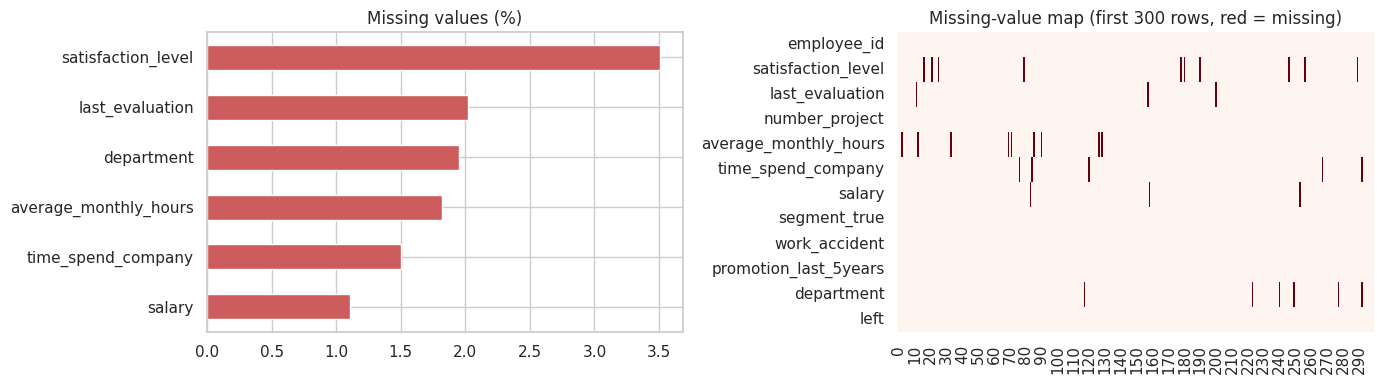

In [5]:
# --- missing values ---
miss = pd.DataFrame({'missing': raw.isna().sum(), 'missing_%': (raw.isna().mean() * 100).round(2)})
display(miss[miss['missing'] > 0].sort_values('missing', ascending=False))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
miss[miss['missing'] > 0]['missing_%'].sort_values().plot(kind='barh', color='indianred', ax=ax[0], title='Missing values (%)')
sns.heatmap(raw.isna().iloc[:300].T, cbar=False, cmap='Reds', ax=ax[1]); ax[1].set_title('Missing-value map (first 300 rows, red = missing)')
plt.tight_layout(); plt.show()

In [6]:
# --- duplicates ---
print('Fully duplicated rows      :', raw.duplicated().sum())
print('Duplicated employee_id     :', raw['employee_id'].duplicated().sum())

# --- text columns: inconsistent spelling? ---
for col in ['department', 'salary']:
    print(f"\n'{col}' has {raw[col].nunique()} different values:")
    print(raw[col].value_counts(dropna=False).to_dict())

Fully duplicated rows      : 40
Duplicated employee_id     : 40

'department' has 28 different values:
{'sales': 339, 'technical': 242, 'IT': 170, 'support': 156, 'marketing': 100, 'hr': 91, 'accounting': 84, 'Sales': 40, 'SALES': 31, ' sales ': 30, nan: 30, 'tech': 26, 'SUPPORT': 24, 'Technical': 22, 'TECHNICAL': 15, 'MARKETING': 15, 'It': 13, 'Support': 13, 'Marketing': 13, ' technical ': 13, ' support ': 10, 'ACCOUNTING': 10, 'Accounting': 10, ' IT ': 9, 'Hr': 9, ' marketing ': 7, ' accounting ': 7, ' hr ': 5, 'HR': 4}

'salary' has 12 different values:
{'medium': 448, 'low': 336, 'high': 257, 'medium ': 88, 'Medium': 65, 'MEDIUM': 62, 'Low': 50, 'low ': 49, 'LOW': 49, 'HIGH': 43, 'High': 37, 'high ': 37, nan: 17}


In [7]:
# --- wrong data types ---
print('Column types:')
print(raw.dtypes.to_string())
bad_hours = pd.to_numeric(raw['average_monthly_hours'], errors='coerce').isna() & raw['average_monthly_hours'].notna()
print('\nHours written as text (e.g. "210 hrs"):', int(bad_hours.sum()), '->', raw.loc[bad_hours, 'average_monthly_hours'].head(3).tolist())

# --- impossible values (business rules) ---
hours = pd.to_numeric(raw['average_monthly_hours'].astype(str).str.extract(r'([-\d.]+)')[0], errors='coerce')
rules = pd.DataFrame([
    ('satisfaction_level should be 0 to 1',       int((raw['satisfaction_level'] > 1).sum() + (raw['satisfaction_level'] < 0).sum())),
    ('last_evaluation should be 0 to 1',          int(((raw['last_evaluation'] > 1) | (raw['last_evaluation'] < 0)).sum())),
    ('average_monthly_hours should be 1 to 400',  int(((hours <= 0) | (hours > 400)).sum())),
    ('time_spend_company should be 0 to 50 years', int(((raw['time_spend_company'] < 0) | (raw['time_spend_company'] > 50)).sum())),
    ('number_project should be 1 to 10',          int(((raw['number_project'] < 1) | (raw['number_project'] > 10)).sum())),
], columns=['rule', 'rows breaking the rule'])
display(rules)

Column types:
employee_id                int64
satisfaction_level       float64
last_evaluation          float64
number_project           float64
average_monthly_hours        str
time_spend_company       float64
salary                       str
segment_true                 str
work_accident              int64
promotion_last_5years      int64
department                   str
left                       int64

Hours written as text (e.g. "210 hrs"): 12 -> ['158 hrs', '169 hrs', '118 hrs']


,rule,rows breaking the rule
0,satisfaction_level should be 0 to 1,5
1,last_evaluation should be 0 to 1,3
2,average_monthly_hours should be 1 to 400,8
3,time_spend_company should be 0 to 50 years,4
4,number_project should be 1 to 10,0


**Findings:** missing values in 6 columns, 40 duplicated employees, text written in different ways (`Sales`, `SALES`, `' sales '`, `tech` / `technical`), some hours stored as text, and impossible values (satisfaction written as percent, hours = 999, negative years, evaluation above 1).

### 3. Cleaning
**3.1 Remove duplicated employees**

In [8]:
df = raw.copy()
n0 = len(df)
df = df.drop_duplicates(subset='employee_id', keep='first').reset_index(drop=True)
steps_log.append({'step': 'remove duplicated employees', 'affected': n0 - len(df)})
print('Rows:', n0, '->', len(df))

Rows: 1538 -> 1498


**3.2 Clean the text columns** (remove spaces, same lower case, merge synonyms)

In [9]:
dept_old, sal_old = df['department'].copy(), df['salary'].copy()
df['department'] = df['department'].str.strip().str.lower().replace({'tech': 'technical'})
df['salary'] = df['salary'].str.strip().str.lower()
changed = int(((dept_old != df['department']) & dept_old.notna()).sum() + ((sal_old != df['salary']) & sal_old.notna()).sum())
print(df['department'].value_counts(dropna=False).to_dict())
print(df['salary'].value_counts(dropna=False).to_dict())
steps_log.append({'step': 'clean text (strip, lower case, merge tech/technical)', 'affected': changed})
print('Text values changed:', changed)

{'sales': 429, 'technical': 312, 'support': 200, 'it': 188, 'marketing': 130, 'accounting': 108, 'hr': 104, nan: 27}
{'medium': 648, 'low': 471, 'high': 363, nan: 16}
Text values changed: 952


**3.3 Convert wrong data types** (`"210 hrs"` -> `210`)

In [10]:
before = int(df['average_monthly_hours'].astype(str).str.contains('[A-Za-z]').sum())      # values like '210 hrs'
df['average_monthly_hours'] = pd.to_numeric(df['average_monthly_hours'].astype(str).str.extract(r'([-\d.]+)')[0], errors='coerce')
steps_log.append({'step': 'convert hours to numbers', 'affected': before})
print('Converted:', before, '| dtype now:', df['average_monthly_hours'].dtype)

Converted: 12 | dtype now: float64


**3.4 Impossible values**
- `satisfaction_level` between 1 and 100 was entered as percent -> divide by 100
- everything else outside the allowed range -> set to missing (it is filled in step 3.5)
The allowed ranges are business rules; change them for your own data.

In [11]:
pct = (df['satisfaction_level'] > 1) & (df['satisfaction_level'] <= 100)
df.loc[pct, 'satisfaction_level'] = df.loc[pct, 'satisfaction_level'] / 100
steps_log.append({'step': 'satisfaction written as percent -> /100', 'affected': int(pct.sum())})

limits = {'satisfaction_level': (0, 1), 'last_evaluation': (0, 1), 'average_monthly_hours': (1, 400),
          'time_spend_company': (0, 50), 'number_project': (1, 10)}
for col, (lo, hi) in limits.items():
    bad = (df[col] < lo) | (df[col] > hi)
    df.loc[bad, col] = np.nan
    steps_log.append({'step': f'{col} outside [{lo}, {hi}] -> missing', 'affected': int(bad.sum())})
    print(f'{col:<24} impossible values set to missing: {int(bad.sum())}')

satisfaction_level       impossible values set to missing: 0
last_evaluation          impossible values set to missing: 3
average_monthly_hours    impossible values set to missing: 8
time_spend_company       impossible values set to missing: 4
number_project           impossible values set to missing: 0


**3.5 Fill the missing values**
- numeric columns: **median** (not affected by outliers)
- text columns: **most frequent value** (mode)

(Other options: `KNNImputer`, `IterativeImputer`. For ~2% missing the median is enough. Rows are **not** deleted, so no employee is lost.)

,satisfaction_level,last_evaluation,average_monthly_hours,time_spend_company,department,salary
missing before,54,32,35,27,27,16


Missing values left: 0


,mean before,mean after,std before,std after
satisfaction_level,0.549,0.550,0.233,0.229
last_evaluation,0.732,0.733,0.163,0.161
number_project,4.115,4.115,1.449,1.449
average_monthly_hours,196.807,196.672,48.067,47.510
time_spend_company,4.772,4.758,2.261,2.243


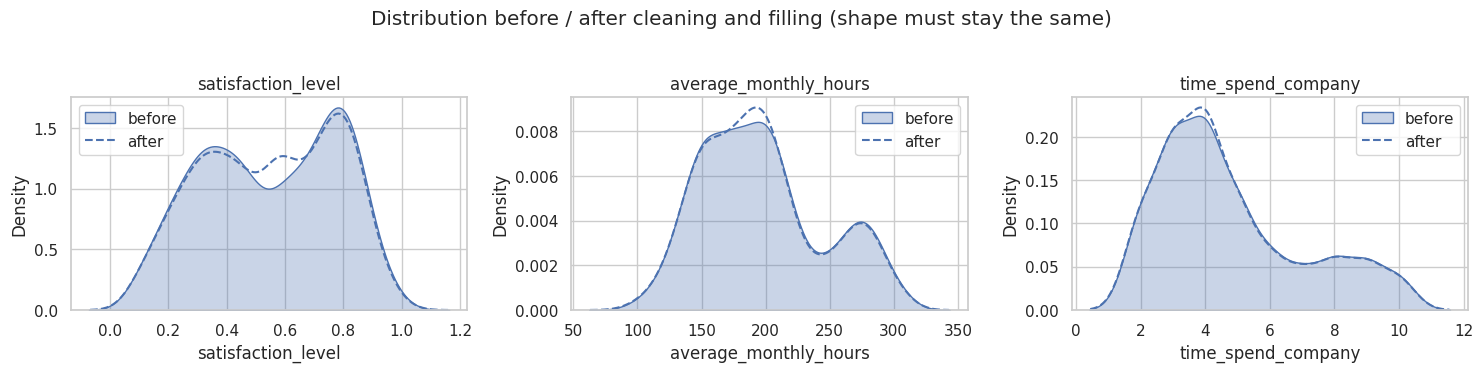

In [12]:
num_cols = ['satisfaction_level', 'last_evaluation', 'number_project', 'average_monthly_hours', 'time_spend_company']
cat_cols = ['department', 'salary']
before_stats = df[num_cols].describe().loc[['mean', 'std']].copy()
n_missing = df[num_cols + cat_cols].isna().sum()
display(n_missing[n_missing > 0].rename('missing before').to_frame().T)

df_before = df.copy()
df[num_cols] = SimpleImputer(strategy='median').fit_transform(df[num_cols])
df[cat_cols] = SimpleImputer(strategy='most_frequent').fit_transform(df[cat_cols])
df['number_project'] = df['number_project'].round(); df['time_spend_company'] = df['time_spend_company'].round()
df['satisfaction_level'] = df['satisfaction_level'].round(2); df['last_evaluation'] = df['last_evaluation'].round(2)
steps_log.append({'step': 'fill missing values (median / mode)', 'affected': int(n_missing.sum())})

print('Missing values left:', int(df[num_cols + cat_cols].isna().sum().sum()))
after_stats = df[num_cols].describe().loc[['mean', 'std']]
display(pd.DataFrame({'mean before': before_stats.loc['mean'], 'mean after': after_stats.loc['mean'],
                      'std before': before_stats.loc['std'], 'std after': after_stats.loc['std']}).round(3))

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for a, col in zip(ax, ['satisfaction_level', 'average_monthly_hours', 'time_spend_company']):
    sns.kdeplot(df_before[col].dropna(), ax=a, label='before', fill=True, alpha=0.3)
    sns.kdeplot(df[col], ax=a, label='after', ls='--'); a.set_title(col); a.legend()
plt.suptitle('Distribution before / after cleaning and filling (shape must stay the same)', y=1.03); plt.tight_layout(); plt.show()

### 4. Encoding and columns that must NOT be clustered
- `salary` -> **ordinal** number (low = 0, medium = 1, high = 2), because it has a natural order
- `department` -> stays as text, only used to **describe** the clusters afterwards
- **Never cluster on:** an ID (`employee_id`), an outcome-like column (`left`: it is the *result* we may want to explain later) or the demo truth (`segment_true`)

In [13]:
df['salary_level'] = df['salary'].map({'low': 0, 'medium': 1, 'high': 2}).astype(int)

excluded = {'employee_id': 'identifier', 'left': 'outcome (not a cluster input)', 'segment_true': 'hidden demo truth (only for checking)',
            'department': 'text, used to describe clusters', 'salary': 'replaced by salary_level'}
print('Excluded from clustering:'); [print(f'  {k:<14} -> {v}') for k, v in excluded.items() if k in df.columns]
df[['salary', 'salary_level']].drop_duplicates().sort_values('salary_level')

Excluded from clustering:
  employee_id    -> identifier
  left           -> outcome (not a cluster input)
  segment_true   -> hidden demo truth (only for checking)
  department     -> text, used to describe clusters
  salary         -> replaced by salary_level


,salary,salary_level
7,low,0
0,medium,1
4,high,2


### 5. Outlier analysis
Two common rules: **IQR** (outside Q1 - 1.5 x IQR or Q3 + 1.5 x IQR) and **z-score** (more than 3 standard deviations from the mean).
In clustering, outliers can be real *special cases* (burn-out, very long tenure), so we **flag** them instead of deleting them. K-Means is sensitive to outliers; DBSCAN / OPTICS / HDBSCAN find them as noise. Set `REMOVE_OUTLIERS = True` to delete them anyway.

,IQR outliers,z-score > 3
feature,,
satisfaction_level,0,0
last_evaluation,0,0
number_project,0,0
average_monthly_hours,0,0
time_spend_company,0,0


Employees flagged by IQR in at least one feature: 0 (0.0%)


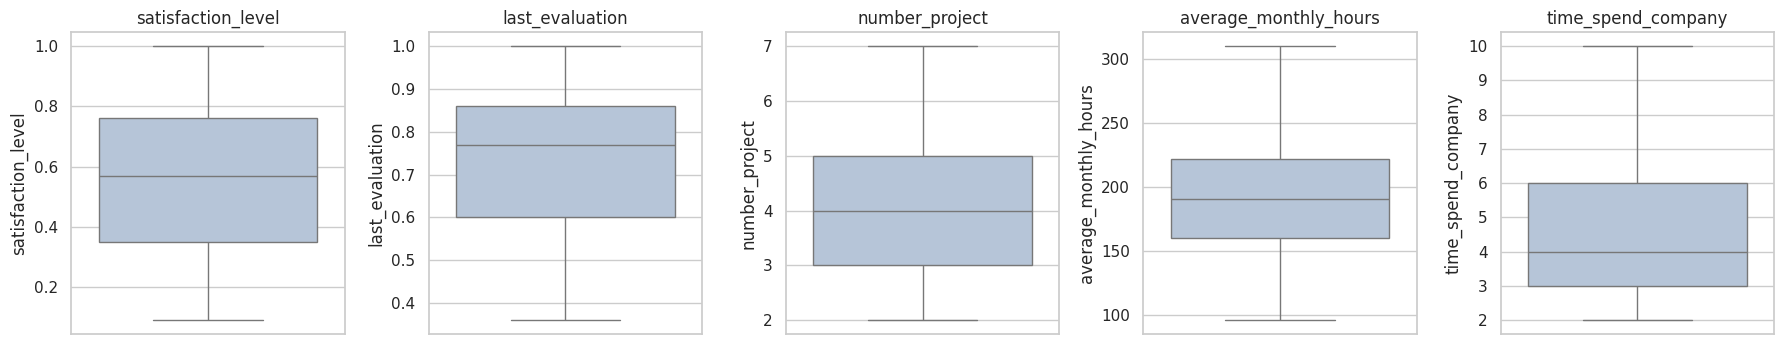

In [14]:
REMOVE_OUTLIERS = False

rows, flag = [], pd.Series(False, index=df.index)
for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75]); iqr = q3 - q1
    f_iqr = (df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)
    f_z = ((df[col] - df[col].mean()) / df[col].std()).abs() > 3
    flag |= f_iqr
    rows.append({'feature': col, 'IQR outliers': int(f_iqr.sum()), 'z-score > 3': int(f_z.sum())})
display(pd.DataFrame(rows).set_index('feature'))
df['is_outlier_iqr'] = flag.astype(int)
print('Employees flagged by IQR in at least one feature:', int(flag.sum()), f'({flag.mean() * 100:.1f}%)')

fig, ax = plt.subplots(1, 5, figsize=(18, 3.6))
for a, col in zip(ax, num_cols):
    sns.boxplot(y=df[col], ax=a, color='lightsteelblue'); a.set_title(col)
plt.tight_layout(); plt.show()

if REMOVE_OUTLIERS:
    df = df[~flag].reset_index(drop=True); print('Rows after removing outliers:', len(df))

**Result:** after cleaning, no feature has extreme values (everything is inside normal ranges). Unusual employees can still exist as **unusual combinations** (for example high satisfaction but 300 hours per month). Column-by-column rules like IQR cannot see them, but **density-based clustering** (DBSCAN, OPTICS, HDBSCAN) can, as noise.

### 6. Feature selection
1. **Correlation:** if two features have |r| > 0.9 they carry the same information (one is dropped).
2. **VIF** (variance inflation factor): above 5 to 10 = multicollinearity.
3. **Continuous-like columns only:** distance- and density-based clustering works best with columns that have many different values. A column with only 2 or 3 values (like `salary_level` or a 0/1 flag) creates "layers" in the data and **splits real groups into pieces** (we saw this with DBSCAN). Rule used here: **at least 5 different values**. Low-value columns are kept to *describe* the clusters, not to build them.

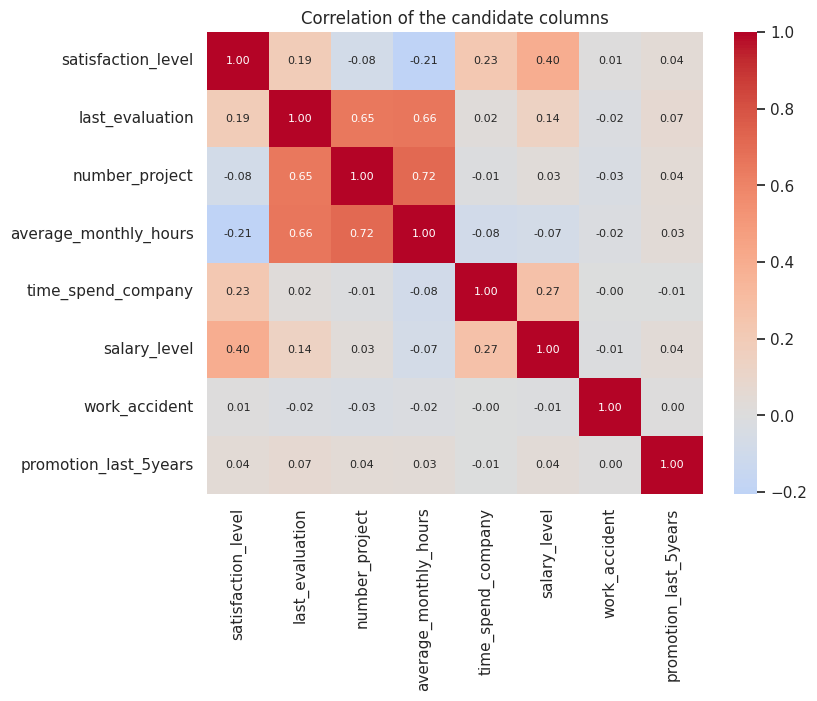

Pairs with |r| > 0.9: none


In [15]:
candidates = ['satisfaction_level', 'last_evaluation', 'number_project', 'average_monthly_hours', 'time_spend_company',
              'salary_level', 'work_accident', 'promotion_last_5years']

# 1) correlation
corr = df[candidates].corr()
plt.figure(figsize=(8, 6)); sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, annot_kws={'size': 8})
plt.title('Correlation of the candidate columns'); plt.show()
pairs = [(a, b, round(corr.loc[a, b], 2)) for i, a in enumerate(candidates) for b in candidates[i + 1:] if abs(corr.loc[a, b]) > 0.9]
print('Pairs with |r| > 0.9:', pairs if pairs else 'none')

In [16]:
# 2) VIF = 1 / (1 - R2) of regressing a feature on all the others
def vif_table(data):
    out = {}
    for c in data.columns:
        others = data.drop(columns=c)
        r2 = LinearRegression().fit(others, data[c]).score(others, data[c])
        out[c] = 1 / (1 - r2)
    return pd.Series(out, name='VIF')

# 3) number of different values per column
nunique = df[candidates].nunique().rename('different values')
summary = pd.concat([nunique, vif_table(df[candidates]).round(2)], axis=1)
summary['used for clustering'] = summary['different values'] >= 5
display(summary)

FEATURES = list(summary.index[summary['used for clustering']])
PROFILE_COLS = FEATURES + ['salary_level']
print('\nFeatures used for clustering:', FEATURES)
print('Extra columns used only to describe the clusters:', ['salary_level', 'work_accident', 'promotion_last_5years', 'department', 'left'])

,different values,VIF,used for clustering
satisfaction_level,90,1.48,True
last_evaluation,65,2.49,True
number_project,6,2.34,True
average_monthly_hours,201,2.76,True
time_spend_company,9,1.10,True
salary_level,3,1.25,False
work_accident,2,1.00,False
promotion_last_5years,2,1.01,False



Features used for clustering: ['satisfaction_level', 'last_evaluation', 'number_project', 'average_monthly_hours', 'time_spend_company']
Extra columns used only to describe the clusters: ['salary_level', 'work_accident', 'promotion_last_5years', 'department', 'left']


### 7. Scaling
Clustering uses **distances**. Without scaling, `average_monthly_hours` (96 to 310) would dominate `satisfaction_level` (0 to 1). We compare three scalers:
- **StandardScaler:** mean 0, std 1 (default choice)
- **RobustScaler:** uses median and IQR (less affected by outliers)
- **MinMaxScaler:** puts every feature between 0 and 1

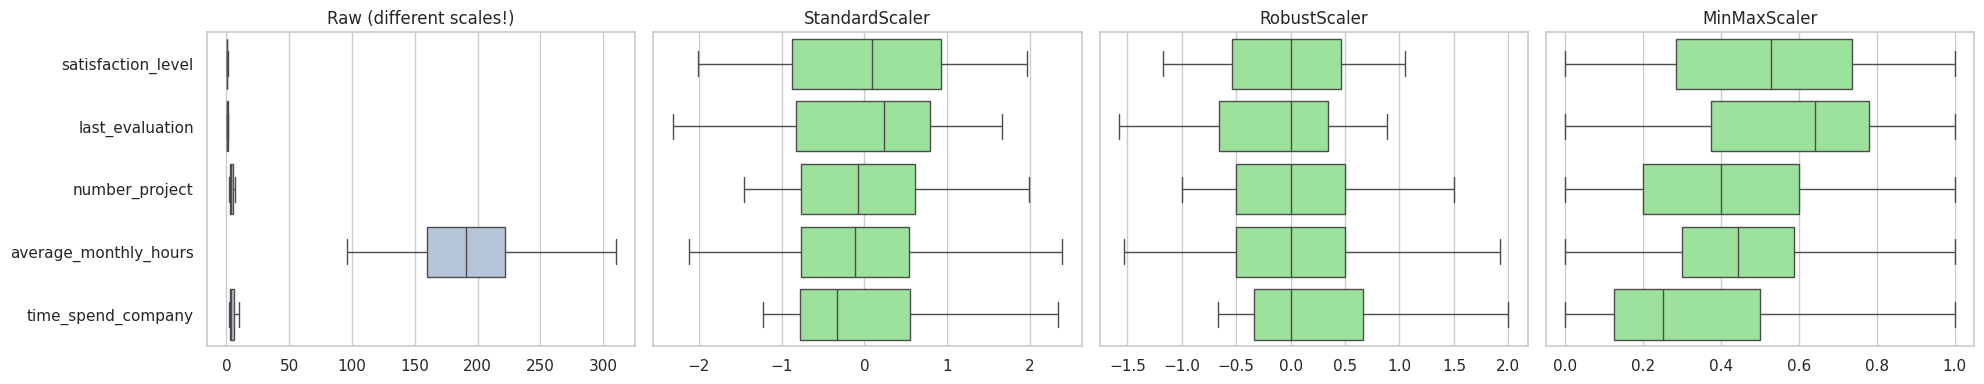

In [17]:
scalers = {'Standard': StandardScaler(), 'Robust': RobustScaler(), 'MinMax': MinMaxScaler()}
fig, ax = plt.subplots(1, 4, figsize=(20, 4))
sns.boxplot(data=df[FEATURES], orient='h', ax=ax[0], color='lightsteelblue'); ax[0].set_title('Raw (different scales!)')
for a, (name, sc) in zip(ax[1:], scalers.items()):
    sns.boxplot(data=pd.DataFrame(sc.fit_transform(df[FEATURES]), columns=FEATURES), orient='h', ax=a, color='lightgreen')
    a.set_title(f'{name}Scaler'); a.set_yticklabels([])
plt.tight_layout(); plt.show()

We use **StandardScaler** (the data has no extreme outliers after cleaning, and K-Means / Ward work best with it).

In [18]:
scaler = StandardScaler().fit(df[FEATURES])
X_scaled = pd.DataFrame(scaler.transform(df[FEATURES]), columns=FEATURES)
display(X_scaled.describe().loc[['mean', 'std', 'min', 'max']].round(2))

,satisfaction_level,last_evaluation,number_project,average_monthly_hours,time_spend_company
mean,-0.00,0.00,0.00,0.00,0.00
std,1.00,1.00,1.00,1.00,1.00
min,-2.01,-2.32,-1.46,-2.12,-1.23
max,1.97,1.66,1.99,2.39,2.34


### 8. Does the data have cluster structure? (Hopkins statistic)
Hopkins compares the distance of real points to their nearest neighbour with the distance of **random points** to the nearest real point.
- **about 0.5** = data looks random (no clusters, clustering is not meaningful)
- **0.6 to 0.75** = some structure, but the clusters overlap
- **above 0.75** = clearly clustered data

In [19]:
def hopkins(X, frac=0.1, seed=0):
    rng = np.random.default_rng(seed)
    n, d = X.shape; m = max(5, int(frac * n))
    nn = NearestNeighbors(n_neighbors=2).fit(X)
    real = X[rng.choice(n, m, replace=False)]
    u = nn.kneighbors(real, n_neighbors=2)[0][:, 1]                      # real point -> nearest OTHER real point
    rand = rng.uniform(X.min(0), X.max(0), (m, d))
    w = nn.kneighbors(rand, n_neighbors=1)[0][:, 0]                      # random point -> nearest real point
    return w.sum() / (w.sum() + u.sum())

Xv = X_scaled.values
h_real = np.mean([hopkins(Xv, seed=s) for s in range(20)])
h_rand = np.mean([hopkins(np.random.default_rng(1).uniform(size=Xv.shape), seed=s) for s in range(20)])
print(f'Hopkins statistic of our data       : {h_real:.3f}')
print(f'Hopkins statistic of random data    : {h_rand:.3f}  (about 0.5 = no structure)')
level = 'clearly clustered data' if h_real > 0.75 else ('some cluster structure, but the groups overlap' if h_real > 0.6 else 'almost no cluster structure')
print('->', level, '(clustering is worth trying)' if h_real > 0.6 else '(clustering may not be meaningful)')

Hopkins statistic of our data       : 0.747
Hopkins statistic of random data    : 0.504  (about 0.5 = no structure)
-> some cluster structure, but the groups overlap (clustering is worth trying)


**PCA:** how many dimensions are needed? The first plot shows the variance explained by every component; the second shows the data in 2D (first 2 components), where we can already see groups.

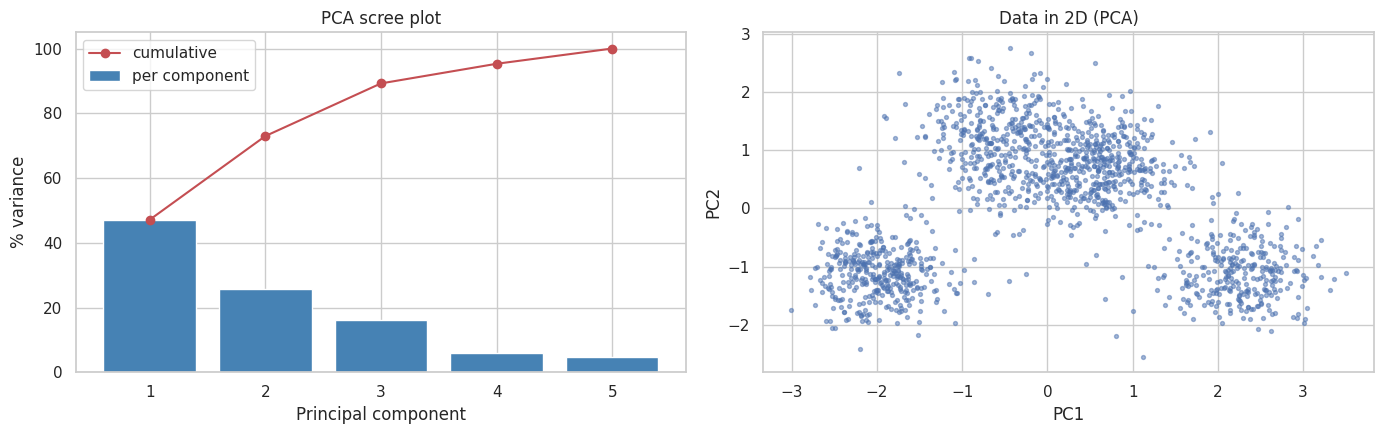

First 2 components explain 72.9 % of the variance.


In [20]:
pca = PCA().fit(Xv); Z = pca.transform(Xv)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].bar(range(1, len(FEATURES) + 1), pca.explained_variance_ratio_ * 100, color='steelblue', label='per component')
ax[0].plot(range(1, len(FEATURES) + 1), np.cumsum(pca.explained_variance_ratio_) * 100, 'ro-', label='cumulative')
ax[0].set_xlabel('Principal component'); ax[0].set_ylabel('% variance'); ax[0].set_title('PCA scree plot'); ax[0].legend()
ax[1].scatter(Z[:, 0], Z[:, 1], s=8, alpha=0.5); ax[1].set_xlabel('PC1'); ax[1].set_ylabel('PC2'); ax[1].set_title('Data in 2D (PCA)')
plt.tight_layout(); plt.show()
print('First 2 components explain', round(pca.explained_variance_ratio_[:2].sum() * 100, 1), '% of the variance.')

### 9. Save the preprocessed data
These files are used by notebooks 02 to 07:

| File | Content |
|---|---|
| `hr_clean.csv` | cleaned data in **original units** (used to describe the clusters) |
| `hr_preprocessed.csv` | **scaled** clustering features (used by the algorithms) |
| `hr_scaler.pkl` | the fitted scaler (needed to prepare **new** employees) |
| `preprocessing_info.json` | feature lists, cleaning log, Hopkins value |
| `hr_truth.csv` | hidden true groups (synthetic demo only, never used for clustering) |

In [21]:
clean_cols = ['employee_id'] + FEATURES + [c for c in ['salary_level', 'work_accident', 'promotion_last_5years'] if c not in FEATURES] \
             + ['department', 'left', 'is_outlier_iqr']
clean = df[clean_cols].copy()
clean.to_csv('hr_clean.csv', index=False)

pre = X_scaled.copy(); pre.insert(0, 'employee_id', df['employee_id'].values)
pre.to_csv('hr_preprocessed.csv', index=False)
joblib.dump(scaler, 'hr_scaler.pkl')

if 'segment_true' in df.columns:
    df[['employee_id', 'segment_true']].to_csv('hr_truth.csv', index=False)

info = {'features': FEATURES, 'profile_cols': PROFILE_COLS, 'rows_raw': int(len(raw)), 'rows_clean': int(len(clean)),
        'hopkins': round(float(h_real), 3), 'scaler': 'StandardScaler', 'remove_outliers': REMOVE_OUTLIERS,
        'excluded_from_clustering': excluded, 'cleaning_log': steps_log}
json.dump(info, open('preprocessing_info.json', 'w'), indent=2)

print('Raw rows:', len(raw), '-> clean rows:', len(clean))
print('Saved: hr_clean.csv, hr_preprocessed.csv, hr_scaler.pkl, preprocessing_info.json' + (', hr_truth.csv' if 'segment_true' in df.columns else ''))
pd.DataFrame(steps_log).set_index('step')

Raw rows: 1538 -> clean rows: 1498
Saved: hr_clean.csv, hr_preprocessed.csv, hr_scaler.pkl, preprocessing_info.json, hr_truth.csv


,affected
step,
remove duplicated employees,40
"clean text (strip, lower case, merge tech/technical)",952
convert hours to numbers,12
satisfaction written as percent -> /100,5
"satisfaction_level outside [0, 1] -> missing",0
"last_evaluation outside [0, 1] -> missing",3
"average_monthly_hours outside [1, 400] -> missing",8
"time_spend_company outside [0, 50] -> missing",4
"number_project outside [1, 10] -> missing",0


In [22]:
clean.head()

,employee_id,satisfaction_level,last_evaluation,number_project,average_monthly_hours,time_spend_company,salary_level,work_accident,promotion_last_5years,department,left,is_outlier_iqr
0,1456,0.87,0.92,4.0,178.0,5.0,1,1,0,technical,0,0
1,1957,0.62,0.68,5.0,150.0,10.0,1,1,1,technical,0,0
2,1612,0.71,0.93,5.0,191.0,4.0,1,0,0,sales,1,0
3,1998,0.64,0.73,3.0,180.0,9.0,1,0,0,support,0,0
4,2037,0.35,0.51,2.0,169.0,2.0,2,0,0,sales,0,0


In [23]:
pre.head()

,employee_id,satisfaction_level,last_evaluation,number_project,average_monthly_hours,time_spend_company
0,1456,1.399342,1.165087,-0.079754,-0.393131,0.108089
1,1957,0.306015,-0.326516,0.610836,-0.982674,2.338353
2,1612,0.699613,1.227237,0.610836,-0.119415,-0.337964
3,1998,0.393481,-0.015766,-0.770345,-0.351021,1.892300
4,2037,-0.874779,-1.383069,-1.460935,-0.582627,-1.230069


### 10. Download (Google Colab only)

In [24]:
try:
    from google.colab import files
    for f in ['hr_clean.csv', 'hr_preprocessed.csv', 'hr_scaler.pkl', 'preprocessing_info.json', 'hr_truth.csv']:
        if os.path.exists(f): files.download(f)
except ImportError:
    print('Not Colab - files are saved in the notebook folder. Keep them in the same folder as notebooks 02 to 07.')

Not Colab - files are saved in the notebook folder. Keep them in the same folder as notebooks 02 to 07.
